# Purchase intent from browsing sessions

Given what a visitor did in a session (pages visited and time on them, Google Analytics bounce, exit and page-value metrics, month, device, traffic source), will the session end in a purchase?

This notebook revisits a 2023 UC Irvine course project (MSBA '24, Team 13B; the team's report is `Machine Learning Final Report.pdf`). That work reported accuracy, which says little here: 84.5% of sessions do not buy, so answering "no purchase" every time already scores 84.5%. This version, written in 2026, measures models on the purchases they find, keeps all preprocessing inside cross-validation, and checks how much of the signal comes from a single feature.

Data: the UCI Online Shoppers Purchasing Intention dataset, 12,330 sessions from one year of one retail site (credits at the end).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
                             confusion_matrix, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import (StratifiedKFold, cross_val_predict, cross_validate,
                                     train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42

df = pd.read_csv("online_shoppers_intention.csv")
y = df.pop("Revenue").astype(int)
X = df.assign(Weekend=df["Weekend"].astype(int))
print(f"{len(X):,} sessions, {X.shape[1]} features, {y.mean():.1%} end in a purchase")

12,330 sessions, 17 features, 15.5% end in a purchase


## Baseline first

A stratified 80/20 split, made before any preprocessing. The test set is used once, at the end. Two numbers any model has to beat: 84.5% accuracy from always answering "no purchase", and a PR-AUC of 0.155 from ranking sessions at random.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Always predict 'no purchase': test accuracy {accuracy_score(y_test, baseline.predict(X_test)):.3f}, "
      "purchases found 0")
print(f"PR-AUC of a random ranking = purchase rate in the test set = {y_test.mean():.3f}")

Always predict 'no purchase': test accuracy 0.845, purchases found 0
PR-AUC of a random ranking = purchase rate in the test set = 0.155


## Features and models

Month, visitor type, operating system, browser, region and traffic type are one-hot encoded, with levels seen fewer than 20 times pooled. The ten numeric features and the weekend flag pass through as they are, scaled only for logistic regression. Encoding and scaling sit inside each pipeline, so no fold is ever fitted with statistics from its own validation part.

Three models, each weighted for the 15/85 class split: logistic regression, a random forest, and gradient-boosted trees. Hyperparameters are set by hand, not tuned.

In [3]:
CATEGORICAL = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
NUMERIC = [c for c in X.columns if c not in CATEGORICAL]


def build(kind, numeric=NUMERIC, categorical=CATEGORICAL):
    """Preprocessing and model in one pipeline, so every fold is fitted on its own training part."""
    steps = []
    if numeric:
        steps.append(("num", StandardScaler() if kind == "logistic regression" else "passthrough", numeric))
    if categorical:
        steps.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                                           sparse_output=False), categorical))
    model = {
        "logistic regression": LogisticRegression(class_weight="balanced", max_iter=5000),
        "random forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=3,
                                                class_weight="balanced_subsample",
                                                random_state=SEED, n_jobs=-1),
        "gradient boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300,
                                                            class_weight="balanced",
                                                            random_state=SEED),
    }[kind]
    return make_pipeline(ColumnTransformer(steps), model)


KINDS = ["logistic regression", "random forest", "gradient boosting"]

## Model choice on cross-validated PR-AUC

Five stratified folds on the training set. PR-AUC (average precision) is the main score because it rewards only finding the 15% who buy; ROC-AUC is shown for reference.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

scores = {}
for kind in KINDS:
    s = cross_validate(build(kind), X_train, y_train, cv=cv, scoring=["average_precision", "roc_auc"])
    scores[kind] = s

table = pd.DataFrame({
    kind: {"PR-AUC": s["test_average_precision"].mean(), "PR-AUC sd": s["test_average_precision"].std(),
           "ROC-AUC": s["test_roc_auc"].mean(), "ROC-AUC sd": s["test_roc_auc"].std()}
    for kind, s in scores.items()}).T.round(3)
best_kind = table["PR-AUC"].idxmax()
print("chosen on cross-validated PR-AUC:", best_kind)
table

chosen on cross-validated PR-AUC: random forest


,PR-AUC,PR-AUC sd,ROC-AUC,ROC-AUC sd
logistic regression,0.657,0.019,0.904,0.007
random forest,0.742,0.019,0.931,0.004
gradient boosting,0.734,0.018,0.927,0.005


## Choosing the cut-off

A purchase flag needs a probability threshold. It is chosen on out-of-fold predictions from the training set (the cut-off with the best F1 for the purchase class), never on the test set.

In [5]:
oof = cross_val_predict(build(best_kind), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, oof)
f1 = 2 * precision * recall / (precision + recall + 1e-12)
i = int(np.argmax(f1[:-1]))
threshold = float(thresholds[i])
print(f"threshold {threshold:.2f}: out-of-fold precision {precision[i]:.3f}, "
      f"recall {recall[i]:.3f}, F1 {f1[i]:.3f}")

threshold 0.52: out-of-fold precision 0.654, recall 0.727, F1 0.689


## Held-out test

One fit on the full training set, one evaluation on the 2,466 test sessions.

In [6]:
final = build(best_kind).fit(X_train, y_train)
p_test = final.predict_proba(X_test)[:, 1]
pred = (p_test >= threshold).astype(int)

print(f"test PR-AUC {average_precision_score(y_test, p_test):.3f}   ROC-AUC {roc_auc_score(y_test, p_test):.3f}")
print(f"test accuracy {accuracy_score(y_test, pred):.3f}   (always 'no purchase': {1 - y_test.mean():.3f})")
default = (p_test >= 0.5).astype(int)
print(f"at the default 0.5 cut: precision {precision_score(y_test, default):.3f}, "
      f"recall {recall_score(y_test, default):.3f}")
print()
print(classification_report(y_test, pred, target_names=["no purchase", "purchase"], digits=3))
pd.DataFrame(confusion_matrix(y_test, pred),
             index=["actual: no purchase", "actual: purchase"],
             columns=["predicted: no purchase", "predicted: purchase"])

test PR-AUC 0.726   ROC-AUC 0.924
test accuracy 0.891   (always 'no purchase': 0.845)
at the default 0.5 cut: precision 0.617, recall 0.704

              precision    recall  f1-score   support

 no purchase      0.943     0.927     0.935      2084
    purchase      0.635     0.696     0.664       382

    accuracy                          0.891      2466
   macro avg      0.789     0.811     0.800      2466
weighted avg      0.896     0.891     0.893      2466



,predicted: no purchase,predicted: purchase
actual: no purchase,1931,153
actual: purchase,116,266


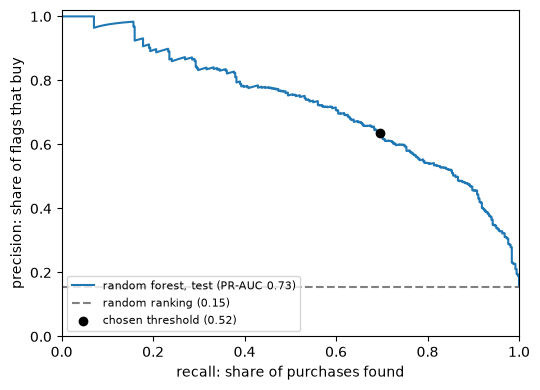

In [7]:
pr, rc, _ = precision_recall_curve(y_test, p_test)
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(rc, pr, label=f"{best_kind}, test (PR-AUC {average_precision_score(y_test, p_test):.2f})")
ax.axhline(y_test.mean(), ls="--", c="grey", label=f"random ranking ({y_test.mean():.2f})")
ax.scatter([recall_score(y_test, pred)], [precision_score(y_test, pred)], c="black", zorder=3,
           label=f"chosen threshold ({threshold:.2f})")
ax.set_xlabel("recall: share of purchases found")
ax.set_ylabel("precision: share of flags that buy")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

## How much rests on PageValues

PageValues is a Google Analytics metric, "the average value for a web page that a user visited before completing an e-commerce transaction" (UCI documentation). It is computed from completed transactions and is highest on pages close to checkout, so it partly measures how far down the funnel a session already got. The check below scores the chosen model with it, without it, and on it alone.

In [8]:
nonzero = (X["PageValues"] > 0).groupby(y).mean()
print(f"sessions with PageValues > 0: {nonzero[1]:.1%} of purchases, {nonzero[0]:.1%} of non-purchases")

variants = {
    "all features": dict(),
    "without PageValues": dict(numeric=[c for c in NUMERIC if c != "PageValues"]),
    "PageValues only": dict(numeric=["PageValues"], categorical=[]),
}
ablation = {}
for name, cols in variants.items():
    s = cross_validate(build(best_kind, **cols), X_train, y_train, cv=cv,
                       scoring=["average_precision", "roc_auc"])
    ablation[name] = {"PR-AUC": s["test_average_precision"].mean(), "ROC-AUC": s["test_roc_auc"].mean()}
pd.DataFrame(ablation).T.round(3)

sessions with PageValues > 0: 80.6% of purchases, 11.4% of non-purchases


,PR-AUC,ROC-AUC
all features,0.742,0.931
without PageValues,0.386,0.787
PageValues only,0.584,0.837


## What this shows

- **Against the baseline.** The random forest reaches a test PR-AUC of 0.73 against 0.155 for a random ranking. At the chosen cut-off it finds 70% of purchasing sessions (266 of 382), and 63% of the sessions it flags go on to buy (266 of 419). Accuracy is 89.1%, 4.6 points above always answering "no purchase", which is why accuracy is not the headline number.
- **Model choice.** Both tree ensembles beat logistic regression by about 0.08 PR-AUC in cross-validation (0.742 and 0.734 against 0.657). The random forest and gradient boosting are within one standard deviation of each other.
- **One feature carries most of it.** Without PageValues, cross-validated PR-AUC falls from 0.742 to 0.386; PageValues alone reaches 0.584. 80.6% of purchasing sessions have a non-zero page value, against 11.4% of the rest. A model used early in a session, before the visitor reaches pages near checkout, should expect results nearer 0.39 than 0.74.
- **Limits.** One retail site over one year, hyperparameters set by hand, and the final numbers come from a single train/test split.

## Credits

- Dataset: Sakar, C. & Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset.* UCI Machine Learning Repository. https://doi.org/10.24432/C5F88Q (CC BY 4.0). Introductory paper: C. O. Sakar, S. Polat, M. Katircioglu and Y. Kastro, "Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks", *Neural Computing and Applications*, 2019.
- The 2023 course report in this repo is the work of MSBA '24 Team 13B at UC Irvine: Ambuj Upadhyay, Akhil Tangutur, Ping-Yen Chung, Yu-Fang Chang and Ziyue Wang. Its preprocessing followed Ben Roshan's public Kaggle notebook, [Online Shopper's Intention | Marketing Analytics](https://www.kaggle.com/code/benroshan/online-shopper-s-intention-marketing-analytics).